In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random

# Generation of two streams of Gaussian Noise
## Stream1

In [4]:
# Gaussian noise stream 1

fs = 2048          
duration = 1.0     # duration of each file in seconds
num_files = 100    # number of 1-second noise files

t_noise = np.arange(0, duration, 1/fs)
mu = 0.0           # mean of Gaussian noise
sigma = 1.0        # standard deviation of Gaussian noise
np.random.seed(71530912)
long_noise_stream1 = np.random.normal(mu, sigma, len(t_noise) * num_files)
noise_array_stream1 = []

i = 0
for n in range(num_files):
    noise = long_noise_stream1[i:i + len(t_noise)]
    noise_array_stream1.append(noise)
    i += len(t_noise)

noise_array_stream1 = np.array(noise_array_stream1)

# Print basic information
print("Shape of Stream 1 noise array:", noise_array_stream1.shape)
print("Number of files:", num_files)
print("Duration of each file:", duration, "s")

Shape of Stream 1 noise array: (100, 2048)
Number of files: 100
Duration of each file: 1.0 s


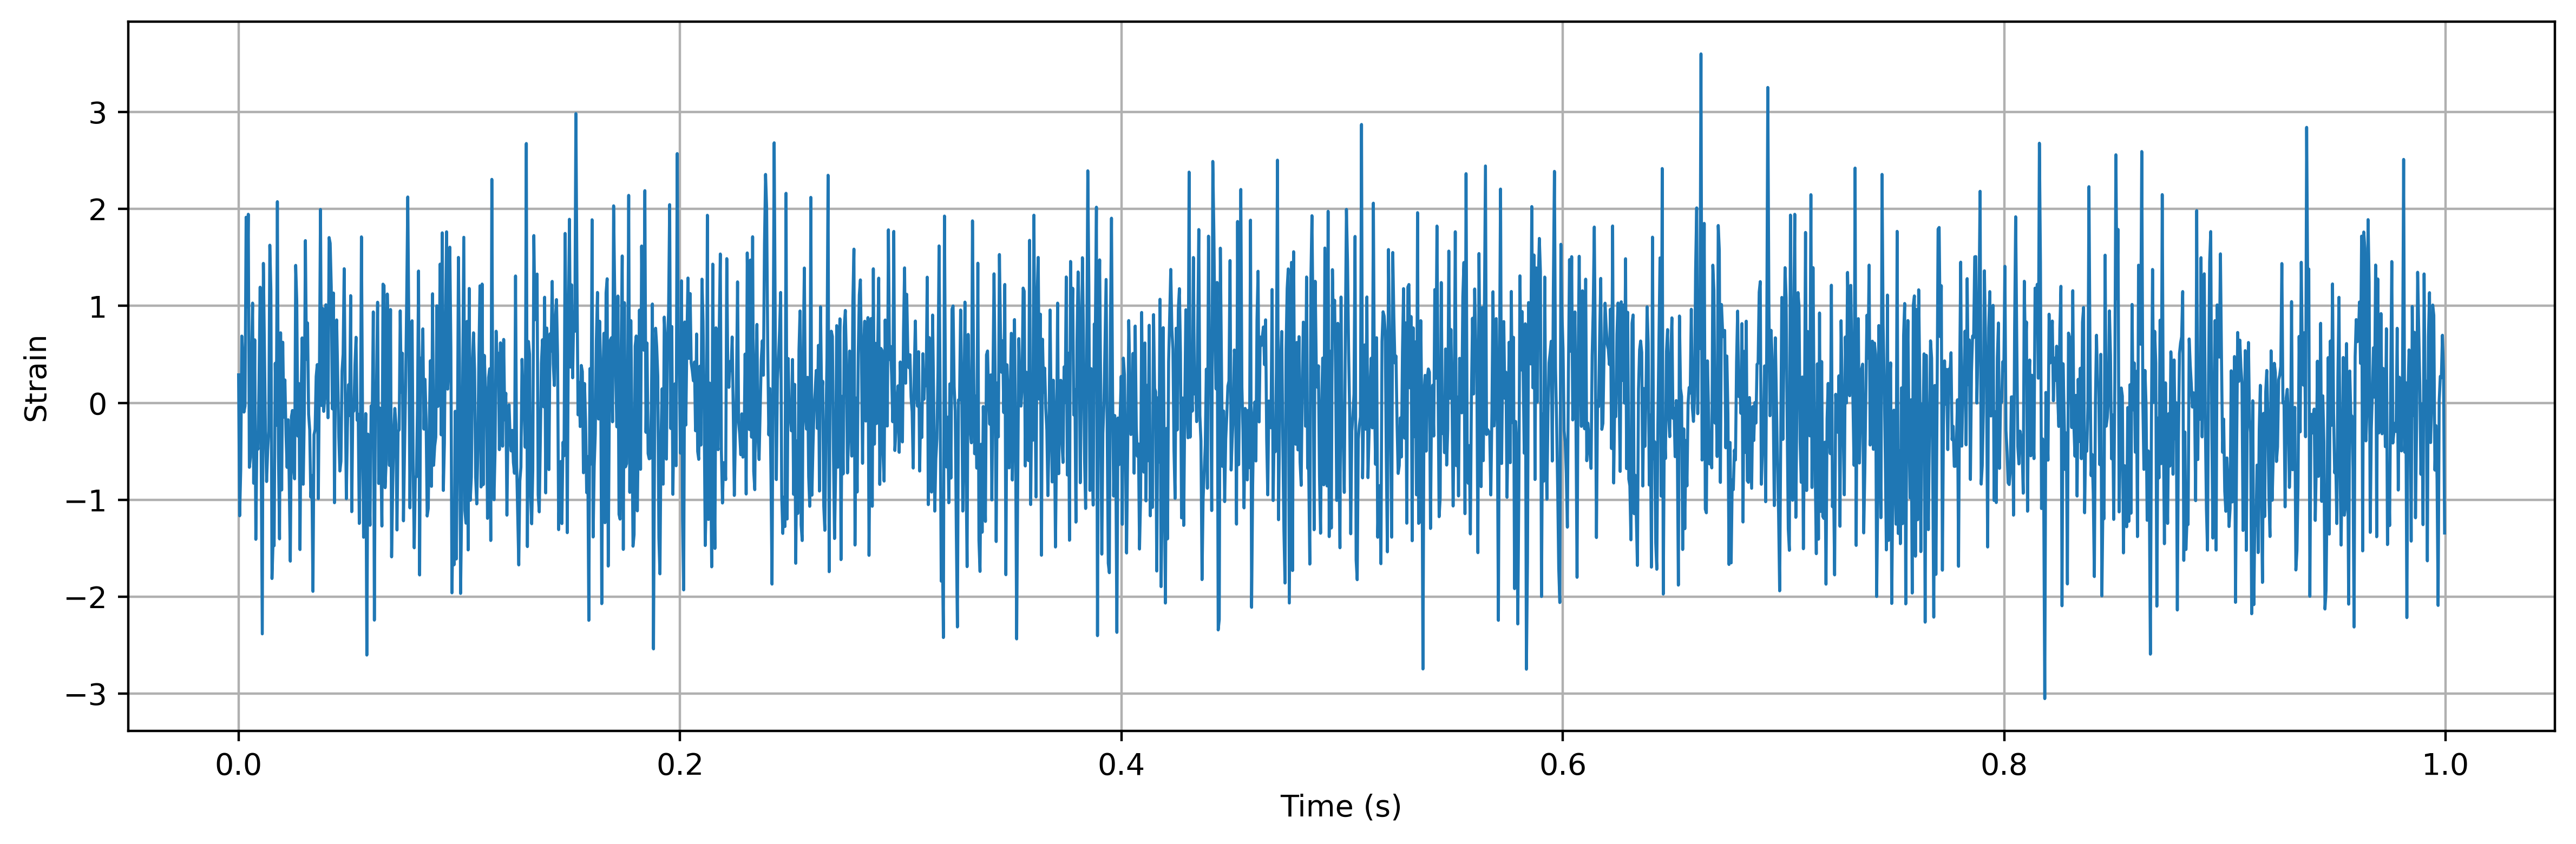

In [5]:
# Plot the first 1-second data from Stream 1

plt.figure(figsize=(12, 4), dpi=400)

plt.plot(t_noise, noise_array_stream1[0], linewidth=1.0)

#plt.title("Gaussian Noise Stream 1 - First 1-Second File")
plt.xlabel("Time (s)")
plt.ylabel("Strain")
plt.grid(True)
plt.tight_layout()
plt.savefig("White_gausssian_noise.png", dpi = 400, bbox_inches = "tight")
plt.show()

## Stream2

In [6]:
# Gaussian noise stream 2

fs = 2048          
duration = 1.0    
num_files = 100    

t_noise = np.arange(0, duration, 1/fs)
mu = 0.0           
sigma = 1.0        
np.random.seed(48206573)
long_noise_stream2 = np.random.normal(mu, sigma, len(t_noise) * num_files)
noise_array_stream2 = []

i = 0
for n in range(num_files):
    noise = long_noise_stream2[i:i + len(t_noise)]
    noise_array_stream2.append(noise)
    i += len(t_noise)

noise_array_stream2 = np.array(noise_array_stream2)
    
# Print basic information
print("Shape of Stream 2 noise array:", noise_array_stream2.shape)
print("Number of files:", num_files)
print("Duration of each file:", duration, "s")

Shape of Stream 2 noise array: (100, 2048)
Number of files: 100
Duration of each file: 1.0 s


## First 1-Second Gaussian Noise Files from Two Independent Streams

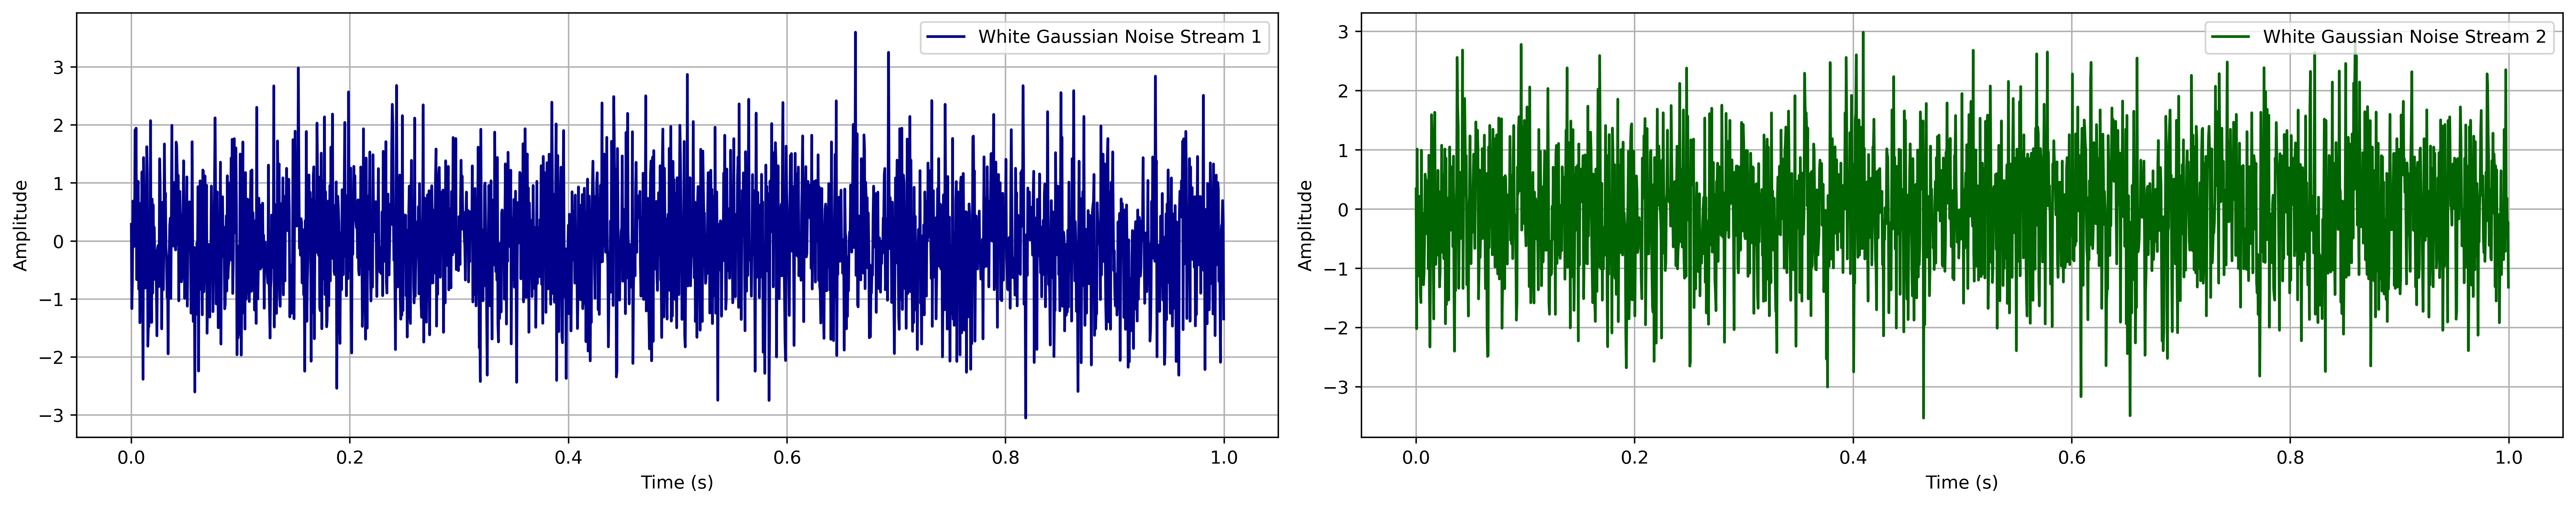

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(20, 4), sharex=True, dpi=400)

# Stream 1 first file
axs[0].plot(
    t_noise,
    noise_array_stream1[0],
    color="darkblue",
    linewidth=1.5,
    label="White Gaussian Noise Stream 1"
)
axs[0].set_xlabel("Time (s)")
axs[0].set_ylabel("Amplitude")
axs[0].grid(True)
axs[0].legend(loc = 'upper right')

# Stream 2 first file
axs[1].plot(
    t_noise,
    noise_array_stream2[0],
    color="darkgreen",
    linewidth=1.5,
    label="White Gaussian Noise Stream 2"
)
axs[1].set_xlabel("Time (s)")
axs[1].set_ylabel("Amplitude")
axs[1].grid(True)
axs[1].legend(loc = 'upper right')

plt.tight_layout()
plt.savefig('Gaussian_noise.png', dpi=400, bbox_inches='tight')
plt.show()

## The Sine-Gaussian Plus Polarization Waveform

In this cell, we define the sine-Gaussian waveform that will later be injected into white Gaussian noise. 
In this simplified case, we use only the plus-polarization component, but we include a parametrization factor using `alpha` and an overall amplitude scaling.

The basic sine-Gaussian component is written as:

$$
H_+(t) =
\exp\left[-\frac{(t-t_0)^2}{\tau^2}\right]
\sin\left[2\pi f_0 (t-t_0)\right]
$$

where:

- f_0 is the central frequency of the waveform,
- t_0 is the central time of the waveform,
- tau controls the duration of the Gaussian envelope.

The characteristic duration tau is defined as:

$$
\tau = \frac{Q}{\sqrt{2}\pi f_0}
$$

where Q is the quality factor. A larger Q gives a longer waveform with more oscillations, while a smaller Q gives a shorter burst.

In the code, we use a parameterized plus-polarization waveform:

$$
h_+(t) =
A \left( \frac{1+\alpha^2}{2} \right) H_+(t)
$$

Therefore, the final waveform used in the code is:

$$
h_+(t) =
A \left( \frac{1+\alpha^2}{2} \right)
\exp\left[-\frac{(t-t_0)^2}{\tau^2}\right]
\sin\left[2\pi f_0 (t-t_0)\right]
$$

In [8]:
f_0SG = np.arange(3, 5000, 1)
QsSG = np.array([3, 9, 100])

# Function to calculate the characteristic duration tau
def SG_tau(Q, f0):
    tau = Q / (np.sqrt(2) * np.pi * f0)
    return tau


# Function to generate plus polarization
def SG_waveform(Q, f0, t, alpha, amplitude, shift):
    tau = SG_tau(Q, f0)

    # Central time of the waveform
    t0 = np.max(t) / 2
    t0 = t0 + shift

    # Shifted time coordinate
    tc = t - t0

    # Basic sine-Gaussian components
    H_plus = np.exp(-(tc**2 / tau**2)) * np.sin(2 * np.pi * f0 * tc)
    h_plus = amplitude * ((1 + alpha**2) / 2) * H_plus
   
    return h_plus

### The SNR of the Injected Signal

In this cell, we define two functions. The first function calculates the signal-to-noise ratio, SNR, of the injected sine-Gaussian waveform. The second function rescales the waveform so that it reaches a desired target SNR.

Since the signal is injected into white Gaussian noise, we use a simple time-domain definition of SNR:

$$
\mathrm{SNR} = \frac{\sqrt{\sum_i h_i^2}}{\sigma_n}
$$

where:

- $h_i$ is the value of the injected waveform at sample $i$,
- $\sigma_n$ is the standard deviation of the Gaussian noise,
- $\sqrt{\sum_i h_i^2}$ represents the total strength of the waveform.

In [9]:
# SNR for white Gaussian noise
def calculate_snr(signal, noise_std=1):
    signal = np.array(signal)
    snr_value = np.sqrt(np.sum(signal**2)) / noise_std
    return snr_value


# Rescale the signal to a desired target SNR
def scale_signal_to_snr(signal, target_snr, noise_std=1):
    signal = np.array(signal)

    current_snr = calculate_snr(signal, noise_std)

    snr = signal * (target_snr / current_snr)

    return snr

### Injection of Sine-Gaussian Signal into Gaussian Noise

In this step, we inject the generated sine-Gaussian signal into the Gaussian noise.

The usual way to inject a signal into noise is:

\[
d(t) = h(t) + n(t)
\]

where:

- \(d(t)\) is the final noisy signal/data,
- \(h(t)\) is the injected sine-Gaussian signal,
- \(n(t)\) is the Gaussian noise.

In the code below, the function takes two inputs: `signal` and `noise`.

For each time sample `i`, it adds:

\[
d_i = h_i + n_i
\]

This is done using:

```python
s_w_n = signal[i] + noise[i]

In [10]:
def AddNoiseToSignal(signal, noise):
    signal_with_noise = []
    for i in range(len(signal)):
        s_w_n = signal[i] + noise[i]
        signal_with_noise.append(s_w_n)

    return signal_with_noise

### Cross-correlation between Two Data Streams

In this step, we define a function to calculate the cross-correlation between two data arrays: `data1` and `data2`.

Cross-correlation is used to measure how similar two signals are when one signal is shifted relative to the other. This is useful because the same gravitational-wave signal may appear in two detectors with a small time delay.

Mathematically, the cross-correlation can be written as:

$$
C(\tau) = \frac{1}{N} \sum_i x_i(t+\tau)y_i(t)
$$

where:

- (C(tau)) is the correlation value for a given time shift,
- (x_i) represents the shifted first data stream,
- (y_i) represents the second data stream,
- (tau) is the lag or time shift,
- (N) is the total number of samples.

In [11]:
def cross_correlation(data1, data2, times):
    correlations = []
    lags = np.arange(-len(times)/2, len(times)/2, 1)
    nx = len(lags)
    nxs = np.arange(-nx//2, nx//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))

        correlation = sum(a * b for a, b in zip(data1_shifted, data2))
        correlation = correlation / len(times)

        correlations.append(correlation)

    return correlations, nxs

In [13]:
## Add signals

signals1 = []
signals2 = []

labels1_fin = []
labels2_fin = []
maxccs = []

target_snr = 10    
f0 = 900             
Q = QsSG[2]         
alpha = 0.8
shift = 0            
fs = 2048
times = np.arange(0, 1, 1/fs)

for i in np.arange(0, num_files, 1):

    # Remove mean from both Gaussian noise streams
    noise1 = noise_array_stream1[i] - np.mean(noise_array_stream1[i])
    noise2 = noise_array_stream2[i] - np.mean(noise_array_stream2[i])

    # Generate sine-Gaussian waveform with amplitude = 1 first
    SG_base = SG_waveform(Q, f0, times, alpha, amplitude=1, shift=shift)

    # Rescale the waveform to the desired SNR
    SG1_fin = scale_signal_to_snr(SG_base, target_snr, noise_std=1)
    SG2_fin = SG1_fin.copy()

    # Create labels for the full 1-second sine-Gaussian signal
    labels1 = np.zeros((len(times), 1))

    for ind in range(len(SG1_fin)):
        if np.abs(SG1_fin[ind]) > 0.0001:
            labels1[ind] = 1

    # Find the signal region
    ints_sig1 = np.where(labels1 == 1)[0]

    # Cut a smaller section around the signal
    start = 1024 - int(len(ints_sig1) / 2) - 100
    end   = 1024 + int(len(ints_sig1) / 2) + 100

    SG1_fin_sec = SG1_fin[start:end]
    SG2_fin_sec = SG2_fin[start:end]

    noise1_sec = noise1[start:end]
    noise2_sec = noise2[start:end]

    times_sig = np.arange(0, len(SG1_fin_sec) / fs, 1 / fs)

    # Add sine-Gaussian signal to Gaussian noise
    sg1 = AddNoiseToSignal(SG1_fin_sec, noise1_sec)
    sg2 = AddNoiseToSignal(SG2_fin_sec, noise2_sec)

    # Split full noise streams into four sections
    noise1_sec1 = noise1[0:512]
    noise1_sec2 = noise1[512:1024]
    noise1_sec3 = noise1[1024:1536]
    noise1_sec4 = noise1[1536:2048]

    noise2_sec1 = noise2[0:512]
    noise2_sec2 = noise2[512:1024]
    noise2_sec3 = noise2[1024:1536]
    noise2_sec4 = noise2[1536:2048]

    # Cross-correlate injected signal section
    ccsig = cross_correlation(sg1, sg2, times_sig)

    # Cross-correlate noise-only sections
    ccnoise1 = cross_correlation(noise1_sec1, noise2_sec1, times[0:512])
    ccnoise2 = cross_correlation(noise1_sec2, noise2_sec2, times[512:1024])
    ccnoise3 = cross_correlation(noise1_sec3, noise2_sec3, times[1024:1536])
    ccnoise4 = cross_correlation(noise1_sec4, noise2_sec4, times[1536:2048])

    # Concatenate noise correlations and signal correlation
    final_sig = np.concatenate((ccnoise1[0],ccnoise2[0],ccsig[0],ccnoise3[0],ccnoise4[0]))

    # Labels for final concatenated cross-correlation stream
    labels = np.zeros((len(final_sig), 1))
    labels[len(ccnoise1[0]) + len(ccnoise2[0]) : len(ccnoise1[0]) + len(ccnoise2[0]) + len(ccsig[0])] = 1
    

    # Save data
    np.savetxt('../TranAD_MGB/data/SG_COR_LOWF_SNR10/test/' + str(i) + '_SG_COR_LOWF_SNR10_Anomaly_Gaussnoise_test.txt',final_sig)

    np.save('../TranAD_MGB/data/SG_COR_LOWF_SNR10/labels/' + str(i) + '_SG_COR_LOWF_SNR10_Anomaly_Gaussnoise_labels.npy',labels)

    print('saved for ', i)

saved for  0
saved for  1
saved for  2
saved for  3
saved for  4
saved for  5
saved for  6
saved for  7
saved for  8
saved for  9
saved for  10
saved for  11
saved for  12
saved for  13
saved for  14
saved for  15
saved for  16
saved for  17
saved for  18
saved for  19
saved for  20
saved for  21
saved for  22
saved for  23
saved for  24
saved for  25
saved for  26
saved for  27
saved for  28
saved for  29
saved for  30
saved for  31
saved for  32
saved for  33
saved for  34
saved for  35
saved for  36
saved for  37
saved for  38
saved for  39
saved for  40
saved for  41
saved for  42
saved for  43
saved for  44
saved for  45
saved for  46
saved for  47
saved for  48
saved for  49
saved for  50
saved for  51
saved for  52
saved for  53
saved for  54
saved for  55
saved for  56
saved for  57
saved for  58
saved for  59
saved for  60
saved for  61
saved for  62
saved for  63
saved for  64
saved for  65
saved for  66
saved for  67
saved for  68
saved for  69
saved for  70
saved for  71
sa

Length of test file: 2558
Signal block from 1024 to 1533


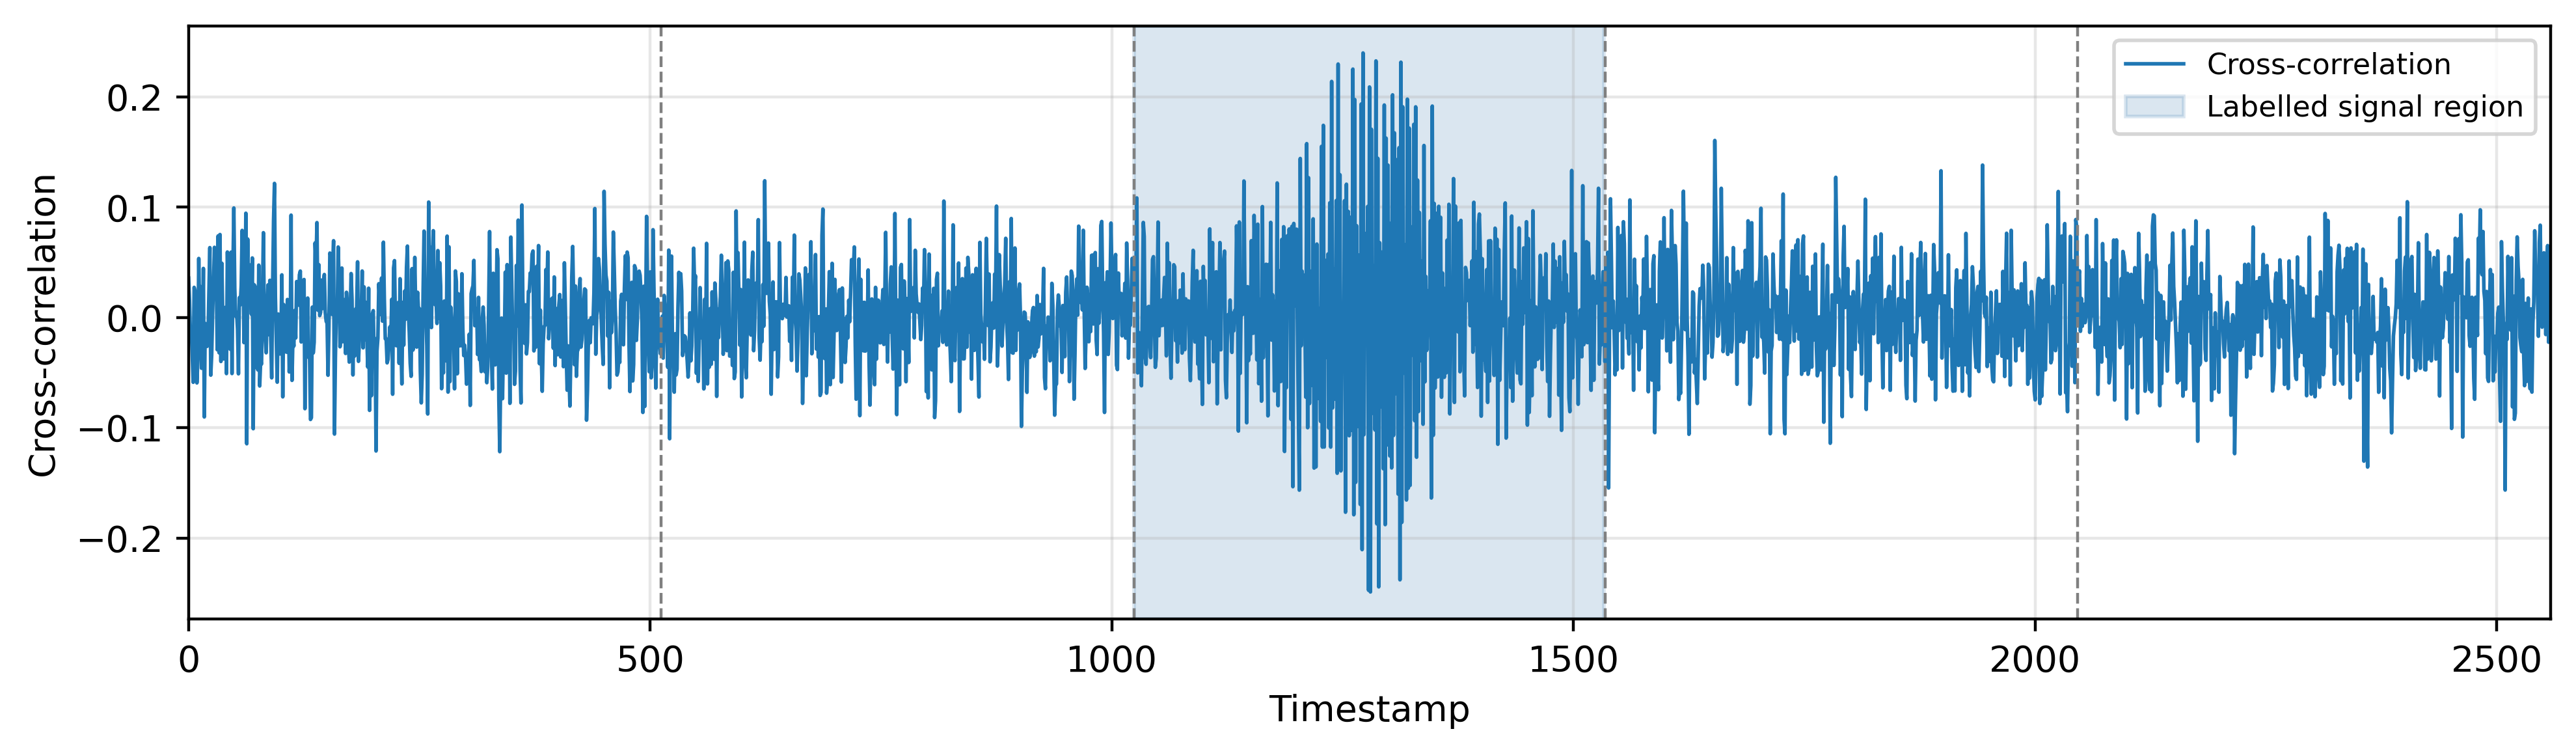

In [14]:
# Plot the first test file (file 0): concatenated cross-correlation with labels

file_index = 0

test_file  = np.loadtxt('../TranAD_MGB/data/SG_COR_LOWF_SNR10/test/' + str(file_index) + '_SG_COR_LOWF_SNR10_Anomaly_Gaussnoise_test.txt')
label_file = np.load('../TranAD_MGB/data/SG_COR_LOWF_SNR10/labels/' + str(file_index) + '_SG_COR_LOWF_SNR10_Anomaly_Gaussnoise_labels.npy')

sequence_index = np.arange(len(test_file))
signal_idx = np.where(label_file[:, 0] == 1)[0]

print("Length of test file:", len(test_file))           # 2558 at 900 Hz, 3142 at 300 Hz
print("Signal block from", signal_idx[0], "to", signal_idx[-1])

plt.figure(figsize=(10, 3), dpi=400)

plt.plot(sequence_index, test_file, linewidth=1.0, label="Cross-correlation")

# Labelled signal block
plt.axvspan(signal_idx[0], signal_idx[-1], color="steelblue", alpha=0.20, label="Labelled signal region")

# Section boundaries: noise 1 | noise 2 | signal | noise 3 | noise 4
for b in [512, signal_idx[0], signal_idx[-1] + 1, signal_idx[-1] + 1 + 512]:
    plt.axvline(b, color="gray", linestyle="--", linewidth=0.8)

plt.xlabel("Timestamp")
plt.ylabel("Cross-correlation")
plt.xlim(0, len(test_file))
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("SG_crosscorrelation_file0.png", dpi=400, bbox_inches="tight")
plt.show()

In [1]:

'''import numpy as np

fs         = 2048
duration   = 1.0
num_files  = 100
times      = np.arange(0, duration, 1/fs)

# ---- Signal parameters ----
target_snr = 10
f0         = 900
Q          = 100
alpha      = 0.8
shift      = -0.125         # t0 = 0.5 - 0.125 = 0.375 s, centre of section 2

name = 'SG_COR_LOWF_SNR10'  # <-- set per configuration

for i in range(num_files):

    # Remove mean from both noise streams
    noise1 = noise_array_stream1[i] - np.mean(noise_array_stream1[i])
    noise2 = noise_array_stream2[i] - np.mean(noise_array_stream2[i])

    # Sine-Gaussian rescaled to the target SNR, same in both detectors
    SG_base = SG_waveform(Q, f0, times, alpha, amplitude=1, shift=shift)
    SG1_fin = scale_signal_to_snr(SG_base, target_snr, noise_std=1)
    SG2_fin = SG1_fin.copy()

    # ---- 1. Inject into the full 1 s file ----
    data1 = noise1 + SG1_fin
    data2 = noise2 + SG2_fin

    # ---- 2. Split into 4 sections, cross-correlate, concatenate ----
    cc1 = cross_correlation(data1[0:512],     data2[0:512],     times[0:512])
    cc2 = cross_correlation(data1[512:1024],  data2[512:1024],  times[512:1024])
    cc3 = cross_correlation(data1[1024:1536], data2[1024:1536], times[1024:1536])
    cc4 = cross_correlation(data1[1536:2048], data2[1536:2048], times[1536:2048])

    final_sig = np.concatenate((cc1[0], cc2[0], cc3[0], cc4[0]))   # 2048 samples

    # Labels: the signal is centred at sample 768, so it lies
    # entirely in section 2 (samples 512 to 1023)
    labels = np.zeros((len(final_sig), 1))
    labels[512:1024] = 1

    np.savetxt('../TranAD_MGB/data/' + name + '/test/' + str(i) + '_' + name + '_Anomaly_Gaussnoise_test.txt', final_sig)
    np.save('../TranAD_MGB/data/' + name + '/labels/' + str(i) + '_' + name + '_Anomaly_Gaussnoise_labels.npy', labels)

    print('saved for', i)'''

"import numpy as np\n\nfs         = 2048\nduration   = 1.0\nnum_files  = 100\ntimes      = np.arange(0, duration, 1/fs)\n\n# ---- Signal parameters ----\ntarget_snr = 10\nf0         = 900\nQ          = 100\nalpha      = 0.8\nshift      = -0.125         # t0 = 0.5 - 0.125 = 0.375 s, centre of section 2\n\nname = 'SG_COR_LOWF_SNR10'  # <-- set per configuration\n\nfor i in range(num_files):\n\n    # Remove mean from both noise streams\n    noise1 = noise_array_stream1[i] - np.mean(noise_array_stream1[i])\n    noise2 = noise_array_stream2[i] - np.mean(noise_array_stream2[i])\n\n    # Sine-Gaussian rescaled to the target SNR, same in both detectors\n    SG_base = SG_waveform(Q, f0, times, alpha, amplitude=1, shift=shift)\n    SG1_fin = scale_signal_to_snr(SG_base, target_snr, noise_std=1)\n    SG2_fin = SG1_fin.copy()\n\n    # ---- 1. Inject into the full 1 s file ----\n    data1 = noise1 + SG1_fin\n    data2 = noise2 + SG2_fin\n\n    # ---- 2. Split into 4 sections, cross-correlate, conca